# Figure 7 — market-graph testbed

Size of the first kernel $\mathcal{K}$ as a function of the input market-graph size $N$
(mean ± std over the testbed instances for each $N$). Each instance samples $N$ assets from the
NIKKEI 225 benchmark `port5` of
[J. E. Beasley's OR-Library](https://people.brunel.ac.uk/~mastjjb/jeb/orlib/portinfo.html)
and thresholds the correlation matrix at its mean correlation. The testbed keeps, for each $N$,
the first 20 seeds (out of 0–39) whose kernel has at most 56 nodes.

Output: `figures/testbed_market_open.png` (release root).

## Before running: download `port5.txt`

The portfolio data is **not included in this release, and this notebook does not download it**.
To run this notebook:

1. Go to the OR-Library portfolio page,
   <https://people.brunel.ac.uk/~mastjjb/jeb/orlib/portinfo.html>, and download `port5.txt`
   (direct link: <https://people.brunel.ac.uk/~mastjjb/jeb/orlib/files/port5.txt>).
2. Save it as `problem_instances/port5.txt` inside this release folder
   (`results_experiments/quantum_informed_portfolio_selection/`).

Reference: T.-J. Chang, N. Meade, J. E. Beasley and Y. M. Sharaiha, *Heuristics for cardinality
constrained portfolio optimisation*, Computers & Operations Research 27 (2000), 1271–1302.

## Market-graph instances used in the paper

You do **not** need `port5.txt` to reproduce the paper's results. The market graphs used in the
experiments ship with this release:

| Path | Content |
|---|---|
| `problem_instances/market/`, `problem_instances/market_extra/` | the 73 market graphs ($N = 26 \dots 44$), as `graphs_N{N}/graph_unweighted_{seed}.graphml` |
| `problem_instances/registries/` | their ground-truth MIS sizes and kernel sizes |

The other notebooks read these files to reproduce the paper's figures and tables. You can also
use them as inputs for your own runs of qReduMIS, e.g.

```python
import networkx as nx
G = nx.read_graphml('problem_instances/market/graphs_N26/graph_unweighted_4.graphml')
```

This notebook is only needed to reproduce Figure 7 or to sample new market graphs from
`port5.txt`.

In [1]:
%matplotlib inline
import os
import sys
import random
from copy import deepcopy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# NetworkX 2.8.8 uses NumPy aliases removed in NumPy 2.0.
for _legacy, _modern in (
    ('float_', 'float64'), ('int_', 'int64'),
    ('complex_', 'complex128'), ('unicode_', 'str_'),
):
    if not hasattr(np, _legacy):
        setattr(np, _legacy, getattr(np, _modern))
import networkx as nx

# Release root: the folder holding problem_instances/ and utils/utils_po.py.
_REL = Path('results_experiments/quantum_informed_portfolio_selection')
for _parent in (Path.cwd(), *Path.cwd().parents):
    for _candidate in (_parent, _parent / _REL):
        if (_candidate / 'problem_instances').is_dir() and (_candidate / 'utils/utils_po.py').is_file():
            BASE = str(_candidate.resolve())
            break
    else:
        continue
    break
else:
    raise FileNotFoundError('Cannot locate the portfolio-selection release (utils/utils_po.py)')
sys.path.insert(0, BASE)
os.chdir(BASE)


def _find_repo_root(start=None):
    """Walk up to the folder holding pyproject.toml and the qReduMIS package."""
    d = os.path.abspath(start or os.getcwd())
    while d != os.path.dirname(d):
        if os.path.isfile(os.path.join(d, 'pyproject.toml')) and (
                os.path.isdir(os.path.join(d, 'qReduMIS_package'))
                or os.path.isdir(os.path.join(d, 'qReduMIS'))):
            return d
        d = os.path.dirname(d)
    raise RuntimeError('Could not locate qReduMIS repo root')


sys.path.insert(0, _find_repo_root())
from qReduMIS.solver.classical_reducer.reducer import Reducer
from utils.utils_po import read_port_data, apply_thresholding, get_asset_graph

SAVE_FIGURES = False  # set False to skip saving figures
FIG_DIR = os.path.join(BASE, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# Portfolio benchmark `port5` (NIKKEI 225) from J. E. Beasley's OR-Library.
# Not shipped with this release and not downloaded by this notebook:
# download it yourself first (see "Before running" above).
PORT5_URL = 'https://people.brunel.ac.uk/~mastjjb/jeb/orlib/files/port5.txt'
PORT5_FILE = os.path.join(BASE, 'problem_instances', 'port5.txt')
if not os.path.isfile(PORT5_FILE):
    raise FileNotFoundError(
        'problem_instances/port5.txt not found. Download the OR-Library\n'
        f'portfolio benchmark from {PORT5_URL}\n'
        f'and save it as {PORT5_FILE}')

n_stocks, returns, Corr, Sigma = read_port_data(file=PORT5_FILE)


def get_small_corr(n, seed):
    """Correlation sub-matrix of n assets sampled with the given seed."""
    random.seed(seed)
    row_indices = random.sample(range(Corr.shape[0]), n)
    return Corr[np.ix_(row_indices, row_indices)]


def get_market_graph(n, seed, threshold=None):
    """Market graph of n assets; the threshold defaults to the mean correlation."""
    small_corr = get_small_corr(n, seed)
    if threshold is None:
        threshold = np.mean(small_corr)
    _, adjacency = apply_thresholding(small_corr, threshold)
    transformed_adjacency = adjacency.astype(float)
    np.fill_diagonal(transformed_adjacency, 0)
    return get_asset_graph(transformed_adjacency), adjacency


In [2]:
## Kernel size of every candidate instance: N = 6, 8, ..., 70 and seeds 0..39
rows = []
for N in range(6, 71, 2):
    for seed in range(40):
        G, _ = get_market_graph(N, seed)
        kernel, _removed, _selected = Reducer(verbose=False).reduce(deepcopy(G))
        rows.append({'N': N, 'seed': seed, 'kernel size': len(kernel.nodes())})
df = pd.DataFrame(rows)

## Testbed: for each N, the first 20 seeds whose kernel has at most 56 nodes
testbed = (df[df['kernel size'] <= 56]
           .sort_values(by='seed')
           .groupby('N')
           .head(20)
           .reset_index(drop=True))
print(f"Testbed: {len(testbed)} instances, N = {testbed['N'].min()}..{testbed['N'].max()}")


Testbed: 660 instances, N = 6..70


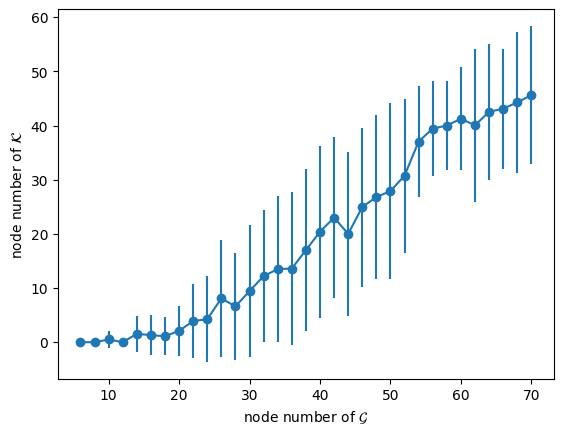

In [3]:
## Fig. 7 -- kernel size vs input graph size (mean ± std over the testbed seeds)
grouped = testbed.groupby('N')['kernel size'].agg(['mean', 'std']).reset_index()

plt.errorbar(grouped['N'], grouped['mean'], yerr=grouped['std'].fillna(0), fmt='-o')
plt.xlabel('node number of $\\mathcal{G}$')
plt.ylabel('node number of $\\mathcal{K}$')
if SAVE_FIGURES:
    plt.savefig(os.path.join(FIG_DIR, 'testbed_market_open.png'), dpi=300, bbox_inches='tight')
plt.show()
